# Zero Flipping: Why One Intensity Can't Give You the Phase

This notebook explains, with complex analysis, why this repo's phase retrieval needs **two**
dispersed measurements $I_1, I_2$, and why they must differ enough.

| § | idea | result |
|---|---|---|
| 1 | a spectrum is a polynomial; its **zeros** fix it | roots in the complex plane |
| 2 | flipping a zero through the unit circle keeps $\lvert X\rvert$ | SymPy identity; 32 signals, one magnitude |
| 3 | time-stretch at large $D$ only sees $\lvert X\rvert$ | flipped signals become indistinguishable |
| 4 | your `retrieve_phase` | fails when $I_1 \approx I_2$, works with diversity |

**References (IEEE)**
1. M. H. Hayes, "The reconstruction of a multidimensional sequence from the phase or magnitude of its Fourier transform," *IEEE Trans. Acoust., Speech, Signal Process.*, vol. 30, no. 2, pp. 140–154, 1982.
2. K. Goda and B. Jalali, "Dispersive Fourier transformation for fast continuous single-shot measurements," *Nat. Photon.*, vol. 7, no. 2, pp. 102–112, 2013.

Module: [`dgs/zero_flip_phase_retrieval.py`](../dgs/zero_flip_phase_retrieval.py)

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.zero_flip_phase_retrieval import (
    zeros_of, flip_zero, all_flips, fourier_magnitude, distinguishability, symbolic_flip_identity,
    max_dispersion_without_wrap,
)
from dgs.gs_core import make_measurements, retrieve_phase
rng = np.random.default_rng(1)
x = rng.normal(size=6) + 1j*rng.normal(size=6)        # a short complex signal, 6 samples

# 1. A spectrum is a polynomial

For a length-$L$ signal, $X(\omega) = \sum_n x[n]\,w^n$ with $w = e^{-j\omega}$. That's a degree-$(L-1)$
polynomial in $w$, evaluated on the **unit circle**. By the fundamental theorem of algebra it's
fixed, up to a constant, by its $L-1$ zeros:

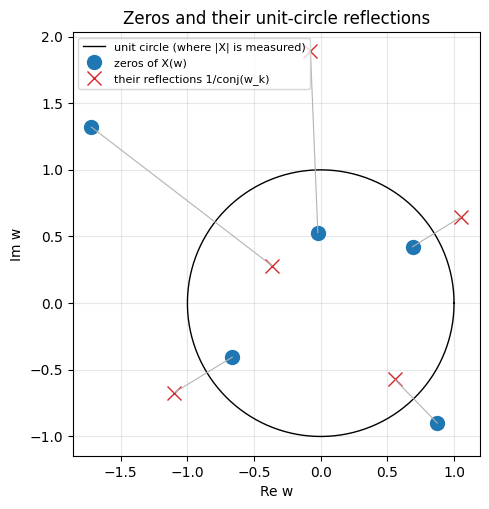

|zeros| = [2.169 0.777 0.529 0.808 1.254]


In [2]:
zk = zeros_of(x)
th = np.linspace(0, 2*np.pi, 400)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(np.cos(th), np.sin(th), "k", lw=1, label="unit circle (where |X| is measured)")
ax.plot(zk.real, zk.imag, "o", ms=10, color="C0", label="zeros of X(w)")
ax.plot((1/np.conj(zk)).real, (1/np.conj(zk)).imag, "x", ms=10, color="C3", label="their reflections 1/conj(w_k)")
for a in zk:
    b = 1/np.conj(a); ax.plot([a.real, b.real], [a.imag, b.imag], "0.7", lw=0.8)
ax.set(aspect="equal", xlabel="Re w", ylabel="Im w", title="Zeros and their unit-circle reflections"); ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
print("|zeros| =", np.round(np.abs(zk), 3))

# 2. Flipping a zero keeps the magnitude

On the unit circle, $|w - a| = |1 - \bar a\,w|$. So swapping the factor $(w - a)$ for $(1 - \bar a w)$,
which moves the zero from $a$ to $1/\bar a$, can't change $|X|$. SymPy proves the identity in general:

In [3]:
expr, (wr, wi, ar, ai) = symbolic_flip_identity()
display(Math(r"|w-a|^2 - |1-\bar a w|^2 = " + sp.latex(expr) + r"\;\xrightarrow{\;|w|=1\;}\; 0"))
F = all_flips(x)
M0 = fourier_magnitude(x)
print(f"{len(F)} signals from flipping subsets of {len(zk)} zeros")
print(f"largest |X| difference among them: {max(np.abs(fourier_magnitude(f) - M0).max() for f in F)/M0.max():.1e} (relative)")
print(f"smallest difference between two of the SIGNALS: {min(np.linalg.norm(F[i]-F[j]) for i in range(len(F)) for j in range(i+1, len(F))):.3f}")

<IPython.core.display.Math object>

32 signals from flipping subsets of 5 zeros
largest |X| difference among them: 1.9e-15 (relative)
smallest difference between two of the SIGNALS: 1.448


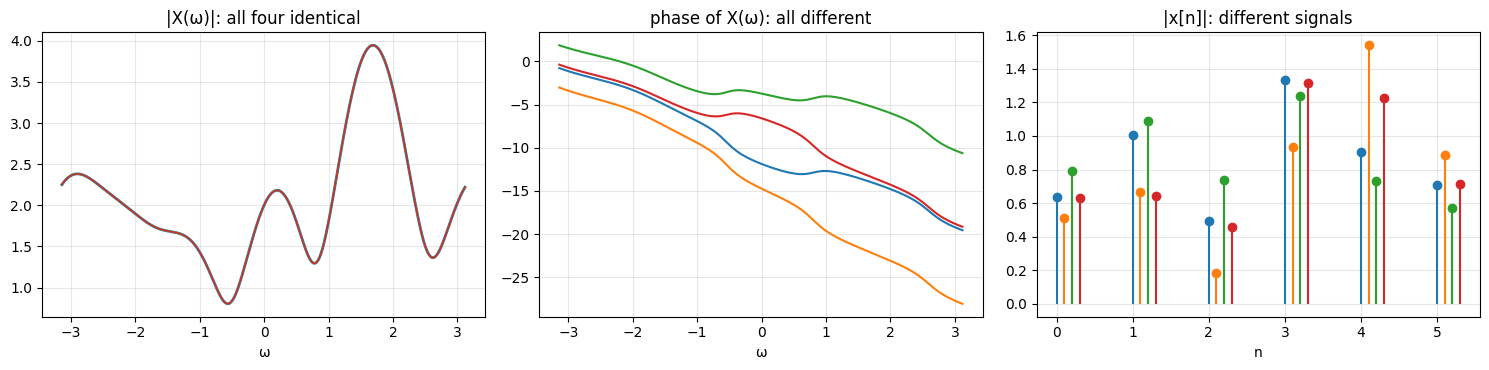

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
w = np.linspace(-np.pi, np.pi, 256, endpoint=False)
for f, col in zip(F[:4], ("C0", "C1", "C2", "C3")):
    Xf = np.fft.fftshift(np.fft.fft(f, 256))
    axes[0].plot(w, np.abs(Xf), col, lw=2 if col == "C0" else 1)
    axes[1].plot(w, np.unwrap(np.angle(Xf)), col)
    axes[2].stem(np.arange(6) + 0.1*"C0C1C2C3".index(col)/2, np.abs(f), linefmt=col, markerfmt=col+"o", basefmt=" ")
axes[0].set(title="|X(ω)|: all four identical", xlabel="ω"); axes[1].set(title="phase of X(ω): all different", xlabel="ω")
axes[2].set(title="|x[n]|: different signals", xlabel="n")
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

With 5 zeros there are $2^5 = 32$ signals sharing **one** Fourier magnitude. Flipping *all* the zeros
gives the time-reversed conjugate, which is the "trivial" ambiguity every phase-retrieval method lives
with. The other 30 are genuinely different signals. A spectrum analyzer can't tell any of them apart.

# 3. Time-stretch only sees $|X|$ in the far field

`disperse(E, D)` applies $H(\nu) = e^{j\pi D\nu^2}$. For large $D$ the output intensity is the
**spectrum mapped onto time**: that's the dispersive Fourier transform behind photonic time-stretch [2].
So a far-field measurement inherits the zero-flip ambiguity. At moderate $D$, the quadratic phase mixes
phase into the intensity, and the flipped signals produce *different* traces:

window N = 65536: |D| must stay below ~218453 to avoid FFT wrap-around


D =        0:  closest pair of flipped signals differs by 13.43 %
D =      300:  closest pair of flipped signals differs by 15.21 %
D =     1000:  closest pair of flipped signals differs by 13.02 %
D =     3000:  closest pair of flipped signals differs by  6.00 %
D =    10000:  closest pair of flipped signals differs by  4.78 %
D =    30000:  closest pair of flipped signals differs by  2.40 %
D =   100000:  closest pair of flipped signals differs by  1.02 %


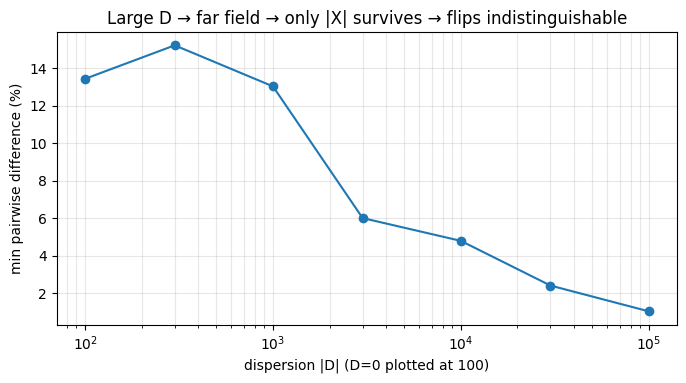

In [5]:
N = 65536
print(f"window N = {N}: |D| must stay below ~{max_dispersion_without_wrap(N):.0f} to avoid FFT wrap-around")
Ds = [0, 300, 1000, 3000, 1e4, 3e4, 1e5]
dist = [distinguishability(F, D, N=N) for D in Ds]
for D, d in zip(Ds, dist):
    print(f"D = {D:>8.0f}:  closest pair of flipped signals differs by {100*d:5.2f} %")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogx(np.maximum(Ds, 100), np.array(dist)*100, "o-")
ax.set(xlabel="dispersion |D| (D=0 plotted at 100)", ylabel="min pairwise difference (%)",
       title="Large D → far field → only |X| survives → flips indistinguishable"); ax.grid(alpha=0.3, which="both"); plt.show()

A numerical lesson came out of this section: with too small a window, the stretched pulse **wraps around**
the periodic FFT grid and the curve turns back up, which is an artifact, not physics. The guard
$|D|\,\nu_\max < N/2$ is now part of the module.

# 4. Your `retrieve_phase`: diversity is what breaks the ambiguity

Two measurements at *different* $D$ constrain the zeros in two different ways, and a zero flip that
fools one doesn't fool the other. If $D_1 \approx D_2$, the second measurement adds almost nothing:

In [6]:
def phase_error(phi, true):
    d = np.angle(np.exp(1j*(phi - true))); d = np.angle(np.exp(1j*(d - np.angle(np.mean(np.exp(1j*d))))))
    return float(np.sqrt(np.mean(d**2)))
rows = []
for D2 in (-5050, -5250, -5750, -7000):
    m = make_measurements("QPSK", D1=-5000, D2=D2, snr_db=40, rng_seed=0)
    phi, _ = retrieve_phase(m["I1"], m["I2"], -5000, D2, n_iter=100, unit_amplitude=m["unit_amplitude"])
    rows.append({"D2 (D1 = -5000)": D2, "corr(I1, I2)": round(float(np.corrcoef(m["I1"], m["I2"])[0, 1]), 4),
                 "RMS phase error (rad)": round(phase_error(phi, m["phi_true"]), 3)})
pd.DataFrame(rows)

,D2 (D1 = -5000),"corr(I1, I2)",RMS phase error (rad)
0,-5050,0.9860,0.840
1,-5250,0.8006,0.679
2,-5750,0.3635,0.013
3,-7000,0.0144,0.015


When the two traces are nearly the same (correlation 0.99), Gerchberg–Saxton can't decide between
ambiguous solutions and the phase error stays large. Once they differ (correlation ≲ 0.4), it locks on.
That's the complex-analysis reason behind the repo's "$|D|$ large, $D_1 \ne D_2$" rules.

## Exercises
1. Put one zero *on* the unit circle. What happens to its flip, and to $|X|$ at that frequency?
2. Count the distinct flips for a *real* signal (zeros come in conjugate pairs). Why are there fewer?
3. Find the smallest $|D_1 - D_2|$ at which `retrieve_phase` succeeds, and relate it to the correlation.